# Intro

* What gradient clipping means, how it works, and what the implications are
* The various learning rate schedulers and how they modify the learning rate during training

# Imports

In [13]:
import numpy as np
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
import torch.nn.functional as F

from transformers import get_cosine_schedule_with_warmup, get_linear_schedule_with_warmup

# vector plots
import matplotlib_inline.backend_inline
matplotlib_inline.backend_inline.set_matplotlib_formats('svg')

# Demo of Gradient Clipping

In [14]:
# tensor with gradeints (like a weights matrix)
w = torch.tensor([[-1,3.3,2,-5,3,-2,-4,-5,1.5]], requires_grad=True)

# loss is sum of squares (L2)
loss = (w**2).sum()

# backprop
loss.backward()

# print the gradients and their norm before clipping
print('BEFORE CLIPPING:')
print(f' Gradient vals: {w.grad[0].tolist()}')
print(f' Gradient norm: {torch.norm(w.grad):.3f}')

# apply gradient clipping
pre_clip_vals = w.grad[0].detach() + 0
nn.utils.clip_grad_norm_([w], max_norm=1)

# print the gradients again
print('\nAFTER CLIPPING:')
print(f' Gradient vals: {w.grad[0].tolist()}')
print(f' Gradient norm: {torch.norm(w.grad):.3f}')

BEFORE CLIPPING:
 Gradient vals: [-2.0, 6.599999904632568, 4.0, -10.0, 6.0, -4.0, -8.0, -10.0, 3.0]
 Gradient norm: 19.712

AFTER CLIPPING:
 Gradient vals: [-0.10146141052246094, 0.3348226547241211, 0.20292282104492188, -0.5073070526123047, 0.3043842315673828, -0.20292282104492188, -0.40584564208984375, -0.5073070526123047, 0.1521921157836914]
 Gradient norm: 1.000


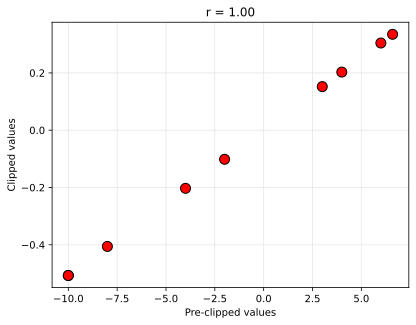

In [15]:
# their correlation
r = torch.corrcoef(torch.cat((pre_clip_vals.unsqueeze(0), w.grad.detach()), dim=0))

plt.plot(pre_clip_vals, w.grad.detach().squeeze(), 'ko', markersize = 10, markerfacecolor = 'r')
plt.gca().set(xlabel='Pre-clipped values', ylabel='Clipped values', title=f'r = {r[0,1]:.2f}')
plt.grid(color = [.9,.9,.9])
plt.show()

# Gradient Clipping Demo During Learning

In [16]:
# training time
training_steps = 80

# define a weight matrix [requires_grad=True to track gradients]
w = torch.tensor([[-4,.2]], requires_grad=True)

# target category
target = torch.tensor([0])

# optimizer and loss function
loss_function = nn.NLLLoss()
optimizer = torch.optim.SGD([w], lr = .03)

#  training iterations
all_weights = torch.zeros((training_steps+1, 2))
all_weights[0,:] = w.detach()
grad_norms = np.zeros((training_steps, 2))

for i in range(training_steps):

  # reset grads
  optimizer.zero_grad()

  # model outputs (simulating a full model forward pass ;))
  model_output = F.log_softmax(w, dim=1)

  # loss
  loss = loss_function(model_output, target)

  # gradient descent
  loss.backward() # calculate gradient of loss wrt w

  # store the gradient norm
  grad_norms[i, 0] = torch.norm(w.grad)

  # engage backprop
  nn.utils.clip_grad_norm_([w], max_norm=1)
  optimizer.step() # adjust w

  # clip the gradient and recalculate its norm
  # nn.utils.clip_grad_norm_([w], max_norm=1)
  grad_norms[i,1] = torch.norm(w.grad)

  # store the new weights
  all_weights[i+1,:] = w.detach()

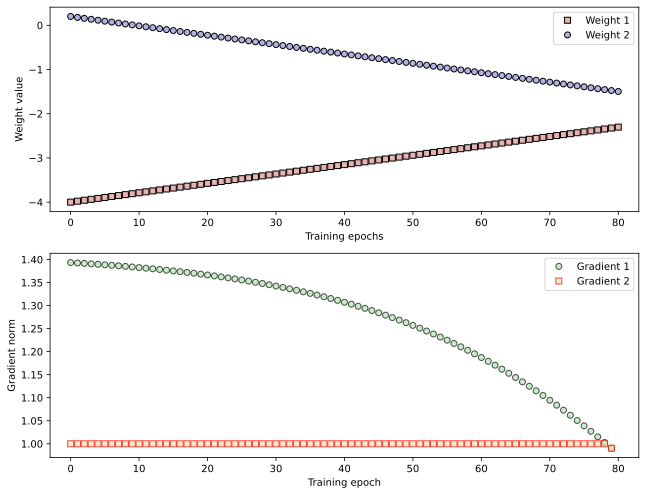

In [17]:
# let's see the weights!
_, axs = plt.subplots(2, 1, figsize=(9, 7))

axs[0].plot(all_weights[:, 0], 'ks', markerfacecolor=[.9, .7, .7], markersize=6, label='Weight 1')
axs[0].plot(all_weights[:, 1], 'ko', markerfacecolor=[.7, .7, .9], markersize=6, label='Weight 2')
axs[0].set(xlabel='Training epochs', ylabel='Weight value', xlim=[-3, training_steps + 3])
axs[0].legend()

axs[1].plot(grad_norms[:, 0], 'ko', markerfacecolor=[.7, .9, .7], markersize=6, alpha=.7, label='Gradient 1')
axs[1].plot(grad_norms[:, 1], 'rs', markerfacecolor=[.9, .9, .7], markersize=6, alpha=.7, label='Gradient 2')
axs[1].set(xlabel='Training epoch', ylabel='Gradient norm', xlim=[-3, training_steps + 3])
axs[1].legend()

plt.tight_layout()
plt.show()

# Demo of Optimizer Scheduler

In [18]:
# training steps
training_steps = 200

# create a "model" and an optimizer
model = nn.Linear(10,10)
optimizer = torch.optim.AdamW(model.parameters(), lr=3e-5)

# learning rate scheduler
scheduler = get_cosine_schedule_with_warmup(
    optimizer,
    num_warmup_steps = int(training_steps*.1), # first 10% of training is warm-up
    num_training_steps = training_steps,
    num_cycles = 1 # in cycles over the entire training course
)

In [19]:
dir(scheduler)

['__annotations__',
 '__class__',
 '__delattr__',
 '__dict__',
 '__dir__',
 '__doc__',
 '__eq__',
 '__firstlineno__',
 '__format__',
 '__ge__',
 '__getattribute__',
 '__getstate__',
 '__gt__',
 '__hash__',
 '__init__',
 '__init_subclass__',
 '__le__',
 '__lt__',
 '__module__',
 '__ne__',
 '__new__',
 '__reduce__',
 '__reduce_ex__',
 '__repr__',
 '__setattr__',
 '__sizeof__',
 '__static_attributes__',
 '__str__',
 '__subclasshook__',
 '__weakref__',
 '_get_lr_called_within_step',
 '_initial_step',
 '_is_initial',
 '_last_lr',
 '_step_count',
 '_update_lr',
 'base_lrs',
 'get_last_lr',
 'get_lr',
 'last_epoch',
 'load_state_dict',
 'lr_lambdas',
 'optimizer',
 'state_dict',
 'step']

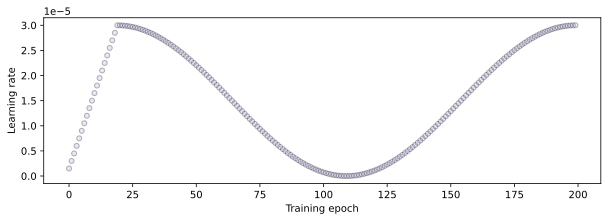

In [20]:
# quick test to see the learning rates
lrs = np.zeros(training_steps)

for i in range(training_steps):

  optimizer.step()
  scheduler.step()
  lrs[i] = scheduler.get_last_lr()[0]

plt.figure(figsize=(10,3))
plt.plot(lrs, 'ko', markersize=5, markerfacecolor=[.7,.7,.9], alpha=.3)
plt.gca().set(xlabel='Training epoch', ylabel='Learning rate')
plt.show()

# Demo of Scheduler in a Learning Model

In [21]:
# redefine training time
training_steps = 5000

# define a weight matrix
w = torch.tensor([[-1., .2]], requires_grad=True)

# target category
target = torch.tensor([0])

# optimizer and loss function
loss_function = nn.NLLLoss()
optimizer = torch.optim.AdamW([w], lr=0.0005)

### --- pick one of these two --- ###

# cosine scheduler with warmup
# scheduler = get_cosine_schedule_with_warmup(
#     optimizer,
#     num_warmup_steps=int(training_steps * 0.2),
#     num_training_steps=training_steps,
#     num_cycles=2
# )

# linear scheduler with warmup
scheduler = get_linear_schedule_with_warmup(
    optimizer,
    num_warmup_steps=int(training_steps * 0.2),
    num_training_steps=training_steps+int(training_steps * 0.15)
)

# training iterations
all_weights = torch.zeros((training_steps + 1, 2))
all_weights[0, :] = w.detach()

lrs = torch.zeros(training_steps)

# training loop
for i in range(training_steps):

    # reset gradients
    optimizer.zero_grad()

    # model output
    model_output = F.log_softmax(w, dim=1)

    # loss
    loss = loss_function(model_output, target)

    # gradient descent
    loss.backward()
    optimizer.step()

    # update scheduler
    scheduler.step()
    lrs[i] = scheduler.get_last_lr()[0]

    # store new weights
    all_weights[i + 1, :] = w.detach()

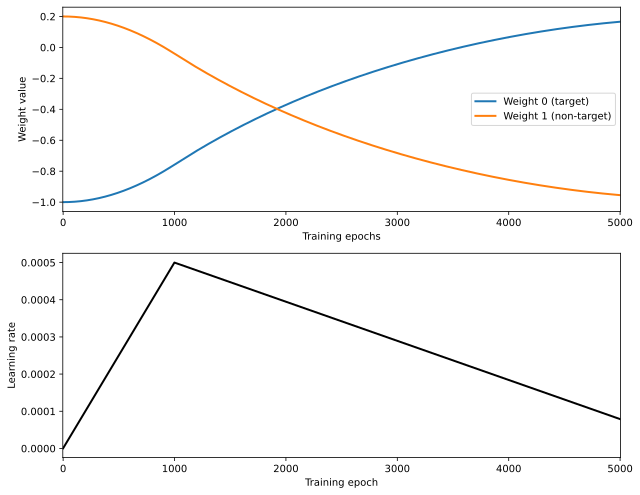

In [22]:
# let's see the weights!
_, axs = plt.subplots(2, 1, figsize=(9, 7))

axs[0].plot(all_weights[:, 0], linewidth=2, label='Weight 0 (target)')
axs[0].plot(all_weights[:, 1], linewidth=2, label='Weight 1 (non-target)')
axs[0].set(
    xlabel='Training epochs',
    ylabel='Weight value',
    xlim=[-3, training_steps + 3]
)
axs[0].legend()

axs[1].plot(lrs, 'k', linewidth=2)
axs[1].set(
    xlabel='Training epoch',
    ylabel='Learning rate',
    xlim=[-3, training_steps + 3]
)

plt.tight_layout()
plt.show()

# Sumup

* Gradient clipping involves scaling down, without fundamentally changing, the gradient magnitude. It slows and stabilizes learning.
* Learning rate schedulers are also designed to slow down and stabilize learning.
* Sometimes, going slower means going faster (fewer errors and better solutions)

# Integration

* How to integrade graddient clipping, learning-rate scheduling, and model fine-tuning
* That appropriate parameter selection requires careful choices, consideration, understanding, visual inspection, and experiemntation